In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

Python: /Users/syed/Desktop/ml-systems-clean/.venv/bin/python3
PyTorch: 2.8.0
MPS available: True


In [8]:
import torch
import torch.nn as nn

torch.manual_seed(42)

x = torch.tensor([2.0, 3.0])

neuron = nn.Linear(2,1) 

print("Input Shape: ", x.shape)
print("Weight Shape: ", neuron.weight.shape)
print("Bias Shape: ", neuron.bias.shape)
print("Initial Output: ", neuron(x))


Input Shape:  torch.Size([2])
Weight Shape:  torch.Size([1, 2])
Bias Shape:  torch.Size([1])
Initial Output:  tensor([2.6763], grad_fn=<ViewBackward0>)


In [13]:
hidden_layer = nn.Linear(1,2)
output_layer = nn.Linear(2,1) 

In [20]:
with torch.no_grad():
    hidden_layer.weight.copy_(torch.tensor([[2.0], [1.0]]))
    hidden_layer.bias.copy_(torch.tensor([-1.0, 1.0]))

    output_layer.weight.copy_(torch.tensor([[5.0, 10.0]]))
    output_layer.bias.copy_(torch.tensor([5.0]))
                              

In [21]:
x = torch.tensor([[3.0]])

z = hidden_layer(x)
h = torch.relu(z)
prediction = output_layer(h)

print("Input:", x)
print("Before ReLU:", z)
print("After ReLU:", h)
print("Predicted score:", prediction.item())

Input: tensor([[3.]])
Before ReLU: tensor([[5., 4.]], grad_fn=<AddmmBackward0>)
After ReLU: tensor([[5., 4.]], grad_fn=<ReluBackward0>)
Predicted score: 70.0


In [22]:
print("Input shape:", x.shape)
print("Hidden weight shape:", hidden_layer.weight.shape)
print("Hidden output shape:", h.shape)
print("Output weight shape:", output_layer.weight.shape)
print("Prediction shape:", prediction.shape)

Input shape: torch.Size([1, 1])
Hidden weight shape: torch.Size([2, 1])
Hidden output shape: torch.Size([1, 2])
Output weight shape: torch.Size([1, 2])
Prediction shape: torch.Size([1, 1])


In [23]:
x = torch.tensor([
    [3.0],
    [5.0]
])

z = hidden_layer(x)
h = torch.relu(z)
predictions = output_layer(h)

print("Input shape:", x.shape)
print("Hidden shape:", h.shape)
print("Prediction shape:", predictions.shape)

print("\nHidden outputs:")
print(h)

print("\nPredictions:")
print(predictions)

Input shape: torch.Size([2, 1])
Hidden shape: torch.Size([2, 2])
Prediction shape: torch.Size([2, 1])

Hidden outputs:
tensor([[5., 4.],
        [9., 6.]], grad_fn=<ReluBackward0>)

Predictions:
tensor([[ 70.],
        [110.]], grad_fn=<AddmmBackward0>)


In [25]:
torch.manual_seed(42)

x_train = torch.linspace(-2,2,41).unsqueeze(1)
y_train = x_train**2

print("Input shape: " , x_train.shape)
print("Output Shape: ", y_train.shape)

print(x_train[:5])
print(y_train[:5])

Input shape:  torch.Size([41, 1])
Output Shape:  torch.Size([41, 1])
tensor([[-2.0000],
        [-1.9000],
        [-1.8000],
        [-1.7000],
        [-1.6000]])
tensor([[4.0000],
        [3.6100],
        [3.2400],
        [2.8900],
        [2.5600]])


In [28]:
model = nn.Sequential(
    nn.Linear(1,16),
    nn.ReLU(),
    nn.Linear(16,1)
)

print(model)

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


In [30]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [33]:
losses = []

for epoch in range(1000):
    predictions = model(x_train)
    loss = loss_fn(predictions, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if epoch%200 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")

print("final loss: ", losses[-1])

Epoch 0, Loss: 0.000926
Epoch 200, Loss: 0.000868
Epoch 400, Loss: 0.000828
Epoch 600, Loss: 0.000799
Epoch 800, Loss: 0.000777
final loss:  0.0007537599303759634


Matplotlib is building the font cache; this may take a moment.


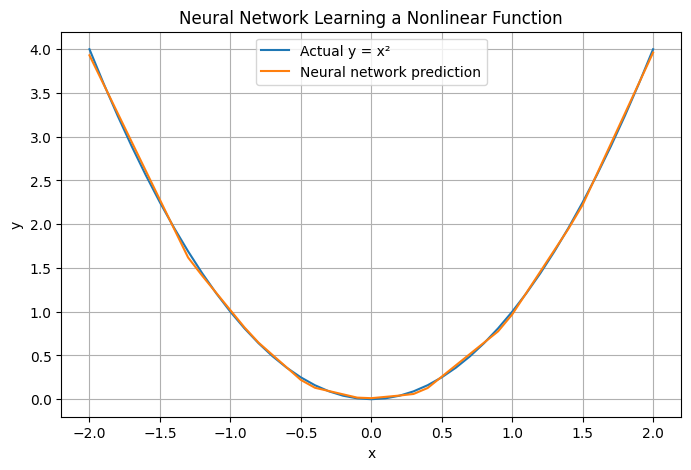

In [39]:
import matplotlib.pyplot as plt
model.eval()

with torch.no_grad():
    predicted_y = model(x_train)

plt.figure(figsize=(8, 5))

plt.plot(
    x_train.numpy(),
    y_train.numpy(),
    label="Actual y = x²"
)

plt.plot(
    x_train.numpy(),
    predicted_y.numpy(),
    label="Neural network prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Neural Network Learning a Nonlinear Function")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
torch.manual_seed(42)

linear_model = nn.Linear(1, 1)

linear_loss_fn = nn.MSELoss()
linear_optimizer = torch.optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

for epoch in range(1000):
    linear_predictions = linear_model(x_train)
    linear_loss = linear_loss_fn(linear_predictions, y_train)

    linear_optimizer.zero_grad()
    linear_loss.backward()
    linear_optimizer.step()

print("Linear model loss:", linear_loss.item())

Linear model loss: 1.565199851989746


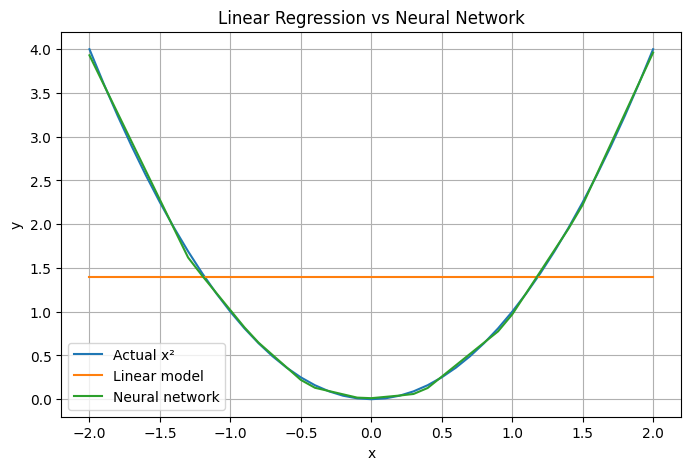

In [41]:
linear_model.eval()

with torch.no_grad():
    linear_y = linear_model(x_train)
    neural_y = model(x_train)

plt.figure(figsize=(8, 5))

plt.plot(x_train.numpy(), y_train.numpy(), label="Actual x²")
plt.plot(x_train.numpy(), linear_y.numpy(), label="Linear model")
plt.plot(x_train.numpy(), neural_y.numpy(), label="Neural network")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression vs Neural Network")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
x_test = torch.tensor([
    [-1.75],
    [-0.35],
    [0.75],
    [1.35]
])

y_test = x_test ** 2

model.eval()

with torch.no_grad():
    predictions = model(x_test)

for x, actual, predicted in zip(x_test, y_test, predictions):
    print(
        f"x={x.item():.2f}, "
        f"Actual={actual.item():.4f}, "
        f"Predicted={predicted.item():.4f}"
    )

test_mse = nn.MSELoss()(predictions, y_test)
print("Test MSE:", test_mse.item())

x=-1.75, Actual=3.0625, Predicted=3.1051
x=-0.35, Actual=0.1225, Predicted=0.1122
x=0.75, Actual=0.5625, Predicted=0.5816
x=1.35, Actual=1.8225, Predicted=1.8274
Test MSE: 0.0005773871089331806
